<a href="https://colab.research.google.com/github/Berisme/Machine_Learning_NguyenHoangPhat_2474802010295/blob/main/Untitled2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 2.3.

In [ ]:
import pandas as pd

df = pd.read_csv("sinh_vien.csv")

print("Kich thuoc bang (so dong, so cot):", df.shape)
print()
print("Nam dong dau tien:")
print(df.head())
print()

 # Cột qua_mon chỉ có hai giá trị, đếm số lần xuất hiện từng giá trị
print("So sinh vien theo ket qua:")
print(df["qua_mon"].value_counts())
print()

print("Ty le qua mon:", round(df["qua_mon"].mean(), 4))
print()

 # So sánh số giờ ôn trung bình của hai nhóm
print("So gio on trung binh theo nhom:")
print(df.groupby("qua_mon")["gio_on"].mean().round(2))

Kich thuoc bang (so dong, so cot): (120, 3)

Nam dong dau tien:
   gio_on  diem_giua_ky  qua_mon
0     5.5           3.0        0
1    19.0           6.0        1
2    14.0           7.7        0
3    11.0           3.1        0
4    10.5           5.8        1

So sinh vien theo ket qua:
qua_mon
1    71
0    49
Name: count, dtype: int64

Ty le qua mon: 0.5917

So gio on trung binh theo nhom:
qua_mon
0     8.29
1    19.89
Name: gio_on, dtype: float64


 3. Hàmsigmoid

3.2. Tự cài đặt và kiểm chứng

In [ ]:
import numpy as np

def sigmoid(z):
  """Ep mot so thuc bat ky ve khoang tu 0 toi 1."""
  return 1 / (1 + np.exp(-z))

print("Bang gia tri cua ham sigmoid")
print(" z sigmoid(z)")
for z in [-6,-4,-2,-1, 0, 1, 2, 4, 6]:

  print(f"{z:3d}  {sigmoid(z):.4f}")
print()

# Hai tính chất cần tự kiểm chứng
print("Kiem tra sigmoid(‐z) = 1‐ sigmoid(z):")
for z in [1.0, 2.5, 3.7]:
  trai = sigmoid(-z)
  phai = 1- sigmoid(z)
  print(f" z = {z}: {trai:.6f} va {phai:.6f}")
print()

# Thử với một mô hình giả định w = 0.4 và b =‐5
w, b = 0.4,-5.0
print(f"Mo hinh gia dinh: w = {w}, b = {b}")
print(" So gio on z = w*x + b Xac suat qua mon")

for gio in [5, 10, 12.5, 15, 20, 25]:
  z = w * gio + b
  print(f" {gio:5.1f} {z:6.2f}  {sigmoid(z):.4f}")

Bang gia tri cua ham sigmoid
 z sigmoid(z)
 -6  0.0025
 -4  0.0180
 -2  0.1192
 -1  0.2689
  0  0.5000
  1  0.7311
  2  0.8808
  4  0.9820
  6  0.9975

Kiem tra sigmoid(‐z) = 1‐ sigmoid(z):
 z = 1.0: 0.268941 va 0.268941
 z = 2.5: 0.075858 va 0.075858
 z = 3.7: 0.024127 va 0.024127

Mo hinh gia dinh: w = 0.4, b = -5.0
 So gio on z = w*x + b Xac suat qua mon
   5.0  -3.00  0.0474
  10.0  -1.00  0.2689
  12.5   0.00  0.5000
  15.0   1.00  0.7311
  20.0   3.00  0.9526
  25.0   5.00  0.9933


 4. Khớp môhình bằng scikit‐lear

  4.1. Ba bước quen thuộc

In [ ]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
df = pd.read_csv("sinh_vien.csv")


# X phải là bảng hai chiều nên viết hai cặp ngoặc vuông.
# y là dãy một chiều nên chỉ một cặp.
X = df[["gio_on"]]
y = df["qua_mon"]

mo_hinh = LogisticRegression()
mo_hinh.fit(X, y)

w = float(mo_hinh.coef_[0][0])
b = float(mo_hinh.intercept_[0])

print(f"He so goc w = {w:.6f}")
print(f"He so chan b = {b:.6f}")
print()

# Số giờ ôn mà mô hình phân vân đúng năm mươi năm mươi
print(f"So gio on ung voi xac suat 0.5: {-b / w:.2f} gio")
print()

can_moi = pd.DataFrame({"gio_on": [5.0, 10.0, 13.0, 20.0, 28.0]})
xac_suat = mo_hinh.predict_proba(can_moi)[:, 1]
nhan = mo_hinh.predict(can_moi)

print("Du doan cho nam ban moi:")
print(" So gio on Xac suat qua  Nhan mo hinh dua ra")
for gio, p, n in zip(can_moi["gio_on"], xac_suat, nhan):
   print(f" {gio:5.1f}  {p:.4f} {n}")

He so goc w = 0.392819
He so chan b = -5.064890

So gio on ung voi xac suat 0.5: 12.89 gio

Du doan cho nam ban moi:
 So gio on Xac suat qua  Nhan mo hinh dua ra
   5.0  0.0431 0
  10.0  0.2429 0
  13.0  0.5104 1
  20.0  0.9422 1
  28.0  0.9974 1


 5.2. Chia dữ liệu rồi chấm điểm

In [9]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,precision_score, recall_score)
from sklearn.model_selection import train_test_split

df = pd.read_csv("sinh_vien.csv")
X = df[["gio_on"]]
y = df["qua_mon"]

# stratify=y giữ đúng tỷ lệ qua và rớt ở cả hai phần sau khi chia
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

print("So sinh vien de hoc: :", len(X_train))
print("So sinh vien de kiem tra:", len(X_test))
print()

mo_hinh = LogisticRegression()
mo_hinh.fit(X_train, y_train)
y_pred = mo_hinh.predict(X_test)

# Thứ tự bốn ô do scikit‐learn quy định là TN, FP, FN, TP
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print("Ma tran nham lan")
print(f" TN = {tn:2d} doan rot, that su rot")
print(f" FP = {fp:2d} doan qua, that ra rot")
print(f" FN = {fn:2d} doan rot, that ra qua")
print(f" TP = {tp:2d} doan qua, that su qua")
print()

print(f"Accuracy = {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision = {precision_score(y_test, y_pred):.4f}")
print(f"Recall = {recall_score(y_test, y_pred):.4f}")
print(f"F1  = {f1_score(y_test, y_pred):.4f}")
print()

# Tự tính lại bằng tay để đối chiếu với thư viện
print("Tu tinh lai bang cong thuc:")
n = len(y_test)
print(f" Accuracy = ({tp} + {tn}) / {n} = {(tp + tn) / n:.4f}")
print(f" Precision = {tp} / ({tp} + {fp}) = {tp / (tp + fp):.4f}")
print(f" Recall= {tp} / ({tp} + {fn}) = {tp / (tp + fn):.4f}")


So sinh vien de hoc: : 90
So sinh vien de kiem tra: 30

Ma tran nham lan
 TN =  9 doan rot, that su rot
 FP =  3 doan qua, that ra rot
 FN =  1 doan rot, that ra qua
 TP = 17 doan qua, that su qua

Accuracy = 0.8667
Precision = 0.8500
Recall = 0.9444
F1  = 0.8947

Tu tinh lai bang cong thuc:
 Accuracy = (17 + 9) / 30 = 0.8667
 Precision = 17 / (17 + 3) = 0.8500
 Recall= 17 / (17 + 1) = 0.9444


6.2. Tự áp ngưỡng


In [10]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("sinh_vien.csv")
X = df[["gio_on"]]
y = df["qua_mon"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y)
mo_hinh = LogisticRegression().fit(X_train, y_train)

p = mo_hinh.predict_proba(X_test)[:, 1]

print("Nguong So ban bi doan la qua Precision Recall")
for nguong in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
  y_pred = (p >= nguong).astype(int)
  pre = precision_score(y_test, y_pred, zero_division=1)
  rec = recall_score(y_test, y_pred, zero_division=0)
  print(f" {nguong:.1f} {y_pred.sum():3d}"
        f"  {pre:.4f}   {rec:.4f}")
print()

print("Doc bang tren tu duoi len:")
print(" Nguong cang cao thi mo hinh cang kho tinh,")
print(" precision tang nhung recall giam. Nguong thap thi nguoc lai.")

Nguong So ban bi doan la qua Precision Recall
 0.2  24  0.7500   1.0000
 0.3  20  0.8500   0.9444
 0.4  20  0.8500   0.9444
 0.5  20  0.8500   0.9444
 0.6  16  1.0000   0.8889
 0.7  15  1.0000   0.8333
 0.8  13  1.0000   0.7222

Doc bang tren tu duoi len:
 Nguong cang cao thi mo hinh cang kho tinh,
 precision tang nhung recall giam. Nguong thap thi nguoc lai.


7.1. Trong mã chỉ đổi đúng một chỗ

In [11]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("sinh_vien.csv")
y = df["qua_mon"]

for ten, cot in [("Mot bien", ["gio_on"]),("Hai bien", ["gio_on", "diem_giua_ky"])]:
  X = df[cot]
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
  mo_hinh = LogisticRegression().fit(X_train, y_train)
  do_chinh_xac = accuracy_score(y_test, mo_hinh.predict(X_test))
  print(f"{ten}: accuracy tren tap kiem tra = {do_chinh_xac:.4f}")
print()

X = df[["gio_on", "diem_giua_ky"]]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
mo_hinh = LogisticRegression().fit(X_train, y_train)

print("He so cua tung bien:")
for ten_cot, he_so in zip(X.columns, mo_hinh.coef_[0]):
  print(f" {ten_cot:14s} {he_so:+.4f}")
print(f" {'he so chan':14s} {mo_hinh.intercept_[0]:+.4f}")
print()
print("Ca hai he so deu duong, nghia la on nhieu hon va")
print("diem giua ky cao hon deu lam tang xac suat qua mon.")

Mot bien: accuracy tren tap kiem tra = 0.8667
Hai bien: accuracy tren tap kiem tra = 0.9000

He so cua tung bien:
 gio_on         +0.3035
 diem_giua_ky   +0.5885
 he so chan     -6.9811

Ca hai he so deu duong, nghia la on nhieu hon va
diem giua ky cao hon deu lam tang xac suat qua mon.


Bài 1

In [12]:
import pandas as pd

df = pd.read_csv("sinh_vien.csv")

# Loc nhom co diem giua ky tu 7 tro len
nhom_cao = df[df["diem_giua_ky"] >= 7]

# Nhom con lai
nhom_con_lai = df[df["diem_giua_ky"] < 7]

# Tinh so luong va ty le qua mon
so_ban = len(nhom_cao)
ty_le_nhom_cao = nhom_cao["qua_mon"].mean()
ty_le_nhom_con_lai = nhom_con_lai["qua_mon"].mean()

print("So ban co diem giua ky tu 7 tro len:", so_ban)
print("Ty le qua mon cua nhom diem tu 7:", round(ty_le_nhom_cao, 4))
print("Ty le qua mon cua nhom con lai:", round(ty_le_nhom_con_lai, 4))

print("Nhan xet: Diem giua ky co kha nang phan biet hai nhom,")
print("vi nhom diem tu 7 tro len co ty le qua mon cao hon.")

So ban co diem giua ky tu 7 tro len: 31
Ty le qua mon cua nhom diem tu 7: 0.9032
Ty le qua mon cua nhom con lai: 0.4831
Nhan xet: Diem giua ky co kha nang phan biet hai nhom,
vi nhom diem tu 7 tro len co ty le qua mon cao hon.


Bài 2

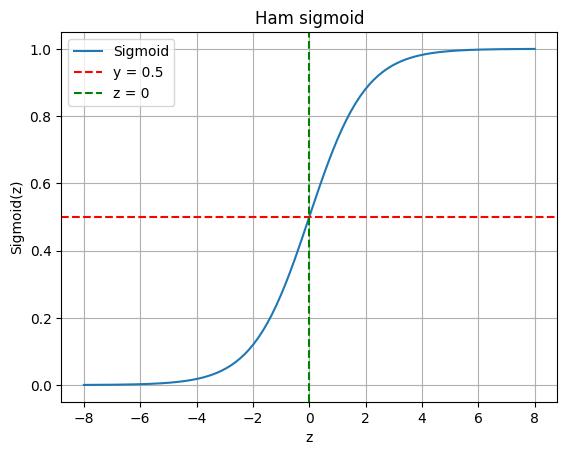

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Tao cac gia tri z tu -8 den 8
z = np.linspace(-8, 8, 200)

# Tinh ham sigmoid
sigmoid = 1 / (1 + np.exp(-z))

# Ve do thi
plt.plot(z, sigmoid, label="Sigmoid")
plt.axhline(y=0.5, color="red", linestyle="--", label="y = 0.5")
plt.axvline(x=0, color="green", linestyle="--", label="z = 0")

plt.xlabel("z")
plt.ylabel("Sigmoid(z)")
plt.title("Ham sigmoid")
plt.legend()
plt.grid(True)

plt.show()

Bài 3

In [15]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression

# Doc du lieu
df = pd.read_csv("sinh_vien.csv")

# Huan luyen mo hinh mot bien
X = df[["gio_on"]]
y = df["qua_mon"]

model = LogisticRegression()
model.fit(X, y)

def du_doan(gio):
    # Tinh z = he so * gio + he so chan
    z = model.coef_[0][0] * gio + model.intercept_[0]

    # Tinh xac suat qua mon
    xac_suat = 1 / (1 + np.exp(-z))

    # Gan nhan theo nguong 0.5
    nhan = 1 if xac_suat >= 0.5 else 0

    print(f"So gio on: {gio}")
    print(f"Gia tri z: {z:.4f}")
    print(f"Xac suat qua mon: {xac_suat:.4f}")
    print(f"Nhan du doan: {nhan}")
    print("-" * 30)

# Du doan cho 5 gia tri
for gio in [3, 8, 12.89, 18, 26]:
    du_doan(gio)

So gio on: 3
Gia tri z: -3.8864
Xac suat qua mon: 0.0201
Nhan du doan: 0
------------------------------
So gio on: 8
Gia tri z: -1.9223
Xac suat qua mon: 0.1276
Nhan du doan: 0
------------------------------
So gio on: 12.89
Gia tri z: -0.0015
Xac suat qua mon: 0.4996
Nhan du doan: 0
------------------------------
So gio on: 18
Gia tri z: 2.0059
Xac suat qua mon: 0.8814
Nhan du doan: 1
------------------------------
So gio on: 26
Gia tri z: 5.1484
Xac suat qua mon: 0.9942
Nhan du doan: 1
------------------------------


Bài 4

In [16]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

df = pd.read_csv("sinh_vien.csv")

X = df[["gio_on"]]
y = df["qua_mon"]

# Neu c4_danh_gia.py dung cach chia du lieu khac,
# hay thay cac tham so nay cho giong file mau.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Lay TP, TN, FP, FN
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
).ravel()

# Tu tinh bang cong thuc
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)

print("TP =", tp, "TN =", tn, "FP =", fp, "FN =", fn)
print("Accuracy =", round(accuracy, 4))
print("Precision =", round(precision, 4))
print("Recall =", round(recall, 4))
print("F1-score =", round(f1, 4))

TP = 12 TN = 8 FP = 2 FN = 2
Accuracy = 0.8333
Precision = 0.8571
Recall = 0.8571
F1-score = 0.8571


Bài 5

In [18]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

df = pd.read_csv("sinh_vien.csv")

X = df[["gio_on"]]
y = df["qua_mon"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = LogisticRegression()
model.fit(X_train, y_train)

# Lay xac suat qua mon tren tap kiem tra
xac_suat = model.predict_proba(X_test)[:, 1]

ket_qua = []

for nguong in np.arange(0.05, 1.0, 0.05):
    y_pred = (xac_suat >= nguong).astype(int)

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    ket_qua.append((nguong, f1))
    print(f"Nguong: {nguong:.2f} | F1: {f1:.4f}")

nguong_tot_nhat, f1_cao_nhat = max(
    ket_qua, key=lambda item: item[1]
)

print("-" * 30)
print(f"Nguong tot nhat: {nguong_tot_nhat:.2f}")
print(f"F1 cao nhat: {f1_cao_nhat:.4f}")

Nguong: 0.05 | F1: 0.7368
Nguong: 0.10 | F1: 0.8235
Nguong: 0.15 | F1: 0.8485
Nguong: 0.20 | F1: 0.8485
Nguong: 0.25 | F1: 0.9333
Nguong: 0.30 | F1: 0.8966
Nguong: 0.35 | F1: 0.8966
Nguong: 0.40 | F1: 0.8966
Nguong: 0.45 | F1: 0.8966
Nguong: 0.50 | F1: 0.8571
Nguong: 0.55 | F1: 0.8462
Nguong: 0.60 | F1: 0.8462
Nguong: 0.65 | F1: 0.8462
Nguong: 0.70 | F1: 0.8462
Nguong: 0.75 | F1: 0.7500
Nguong: 0.80 | F1: 0.7500
Nguong: 0.85 | F1: 0.7500
Nguong: 0.90 | F1: 0.7273
Nguong: 0.95 | F1: 0.7273
------------------------------
Nguong tot nhat: 0.25
F1 cao nhat: 0.9333


Bài 6

In [19]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score

df = pd.read_csv("sinh_vien.csv")

X = df[["gio_on"]]
y = df["qua_mon"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# Danh gia lop 0: rot mon
precision_0 = precision_score(
    y_test, y_pred, pos_label=0, zero_division=0
)

recall_0 = recall_score(
    y_test, y_pred, pos_label=0, zero_division=0
)

# Danh gia lop 1: qua mon
precision_1 = precision_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

recall_1 = recall_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

print("Lop 0 - Rot mon")
print("Precision:", round(precision_0, 4))
print("Recall:", round(recall_0, 4))

print("\nLop 1 - Qua mon")
print("Precision:", round(precision_1, 4))
print("Recall:", round(recall_1, 4))

Lop 0 - Rot mon
Precision: 0.8
Recall: 0.8

Lop 1 - Qua mon
Precision: 0.8571
Recall: 0.8571
